# CyberGuard
## ML-Based IoT Network Attack Detection and Traffic Behavior Analysis

Phase 1 / Dataset Understanding notebook.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print('CyberGuard notebook ready')

CyberGuard notebook ready


In [3]:
data_path = "../data/RT_IOT2022.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully")

Dataset loaded successfully


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 123117
Columns: 85


In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max

In [6]:
df.head()

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


In [7]:
print("Target variable:")
print(df["Attack_type"].head())


Target variable:
0    MQTT_Publish
1    MQTT_Publish
2    MQTT_Publish
3    MQTT_Publish
4    MQTT_Publish
Name: Attack_type, dtype: str


In [8]:
print("Number of classes:", df["Attack_type"].nunique())
print("\nClass names:")
print(df["Attack_type"].unique())

Number of classes: 12

Class names:
<StringArray>
[              'MQTT_Publish',                'Thing_Speak',
                 'Wipro_bulb',             'ARP_poisioning',
             'DDOS_Slowloris',              'DOS_SYN_Hping',
 'Metasploit_Brute_Force_SSH',              'NMAP_FIN_SCAN',
          'NMAP_OS_DETECTION',              'NMAP_TCP_scan',
              'NMAP_UDP_SCAN',        'NMAP_XMAS_TREE_SCAN']
Length: 12, dtype: str


In [9]:
class_counts = df["Attack_type"].value_counts()

print(class_counts)


Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64


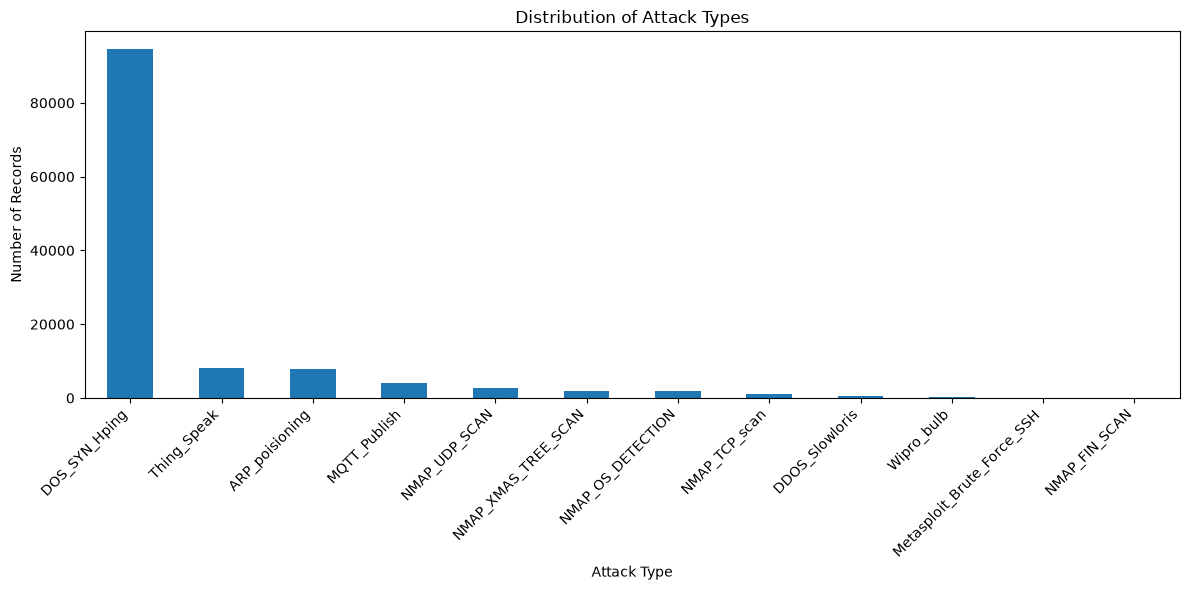

In [10]:
plt.figure(figsize=(12, 6))

df["Attack_type"].value_counts().plot(kind="bar")

plt.title("Distribution of Attack Types")
plt.xlabel("Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
print("Data types:")
print(df.dtypes)

Data types:
Unnamed: 0                int64
id.orig_p                 int64
id.resp_p                 int64
proto                       str
service                     str
                         ...   
idle.std                float64
fwd_init_window_size      int64
bwd_init_window_size      int64
fwd_last_window_size      int64
Attack_type                 str
Length: 85, dtype: object


In [12]:
print("Data type summary:")
print(df.dtypes.value_counts())

Data type summary:
float64    56
int64      26
str         3
Name: count, dtype: int64


In [13]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['proto', 'service', 'Attack_type']


C:\Users\Admin\AppData\Local\Temp\ipykernel_31732\1612948181.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [14]:
missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
Series([], dtype: int64)


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
print("First 10 columns:")
print(df.columns[:10].tolist())

First 10 columns:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot']


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,3.703509e+04,3.045911e+04,0.0,6059.000000,33100.000000,63879.000000,9.465800e+04
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,37221.000000,50971.000000,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,21.000000,21.000000,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,0.000004,0.000005,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000,1.000000,4.345000e+03
...,...,...,...,...,...,...,...,...
idle.avg,123117.0,1.664985e+06,9.007064e+06,0.0,0.000000,0.000000,0.000000,3.000000e+08
idle.std,123117.0,4.550183e+04,1.091361e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,123117.0,6.118905e+03,1.871631e+04,0.0,64.000000,64.000000,64.000000,6.553500e+04
bwd_init_window_size,123117.0,2.739776e+03,1.001885e+04,0.0,0.000000,0.000000,0.000000,6.553500e+04


In [18]:
print("Protocol values:")
print(df["proto"].unique())

print("\nService values:")
print(df["service"].unique())

Protocol values:
<StringArray>
['tcp', 'udp', 'icmp']
Length: 3, dtype: str

Service values:
<StringArray>
['mqtt', '-', 'http', 'dns', 'ntp', 'ssl', 'dhcp', 'irc', 'ssh', 'radius']
Length: 10, dtype: str


Phase 2 — Exploratory Data Analysis (EDA).

In [19]:
class_distribution = df["Attack_type"].value_counts()
class_percentage = df["Attack_type"].value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    "Count": class_distribution,
    "Percentage": class_percentage.round(2)
})

distribution

,Count,Percentage
Attack_type,,
DOS_SYN_Hping,94659,76.89
Thing_Speak,8108,6.59
ARP_poisioning,7750,6.29
MQTT_Publish,4146,3.37
NMAP_UDP_SCAN,2590,2.10
NMAP_XMAS_TREE_SCAN,2010,1.63
NMAP_OS_DETECTION,2000,1.62
NMAP_TCP_scan,1002,0.81
DDOS_Slowloris,534,0.43


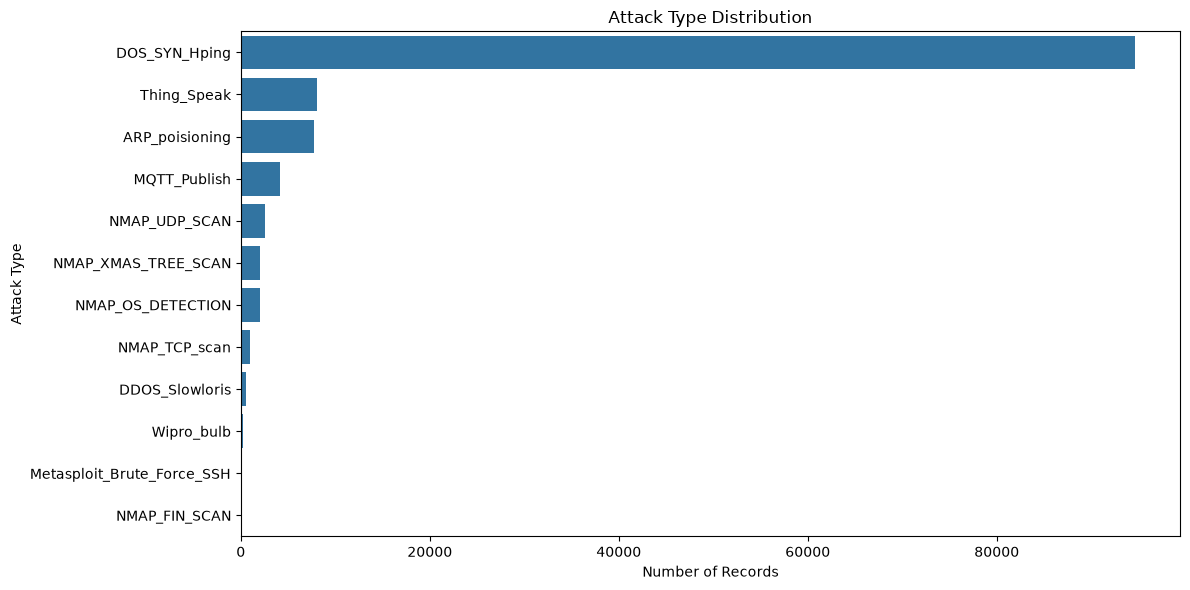

In [20]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Attack_type",
    order=df["Attack_type"].value_counts().index
)

plt.title("Attack Type Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Attack Type")
plt.tight_layout()
plt.show()

In [21]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numeric_columns))
print("\nNumerical columns:")
print(numeric_columns.tolist())

Number of numerical columns: 82

Numerical columns:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.

In [22]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,3.703509e+04,3.045911e+04,0.0,6059.000000,33100.000000,63879.000000,9.465800e+04
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,37221.000000,50971.000000,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,21.000000,21.000000,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,0.000004,0.000005,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000,1.000000,4.345000e+03
...,...,...,...,...,...,...,...,...
idle.avg,123117.0,1.664985e+06,9.007064e+06,0.0,0.000000,0.000000,0.000000,3.000000e+08
idle.std,123117.0,4.550183e+04,1.091361e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,123117.0,6.118905e+03,1.871631e+04,0.0,64.000000,64.000000,64.000000,6.553500e+04
bwd_init_window_size,123117.0,2.739776e+03,1.001885e+04,0.0,0.000000,0.000000,0.000000,6.553500e+04


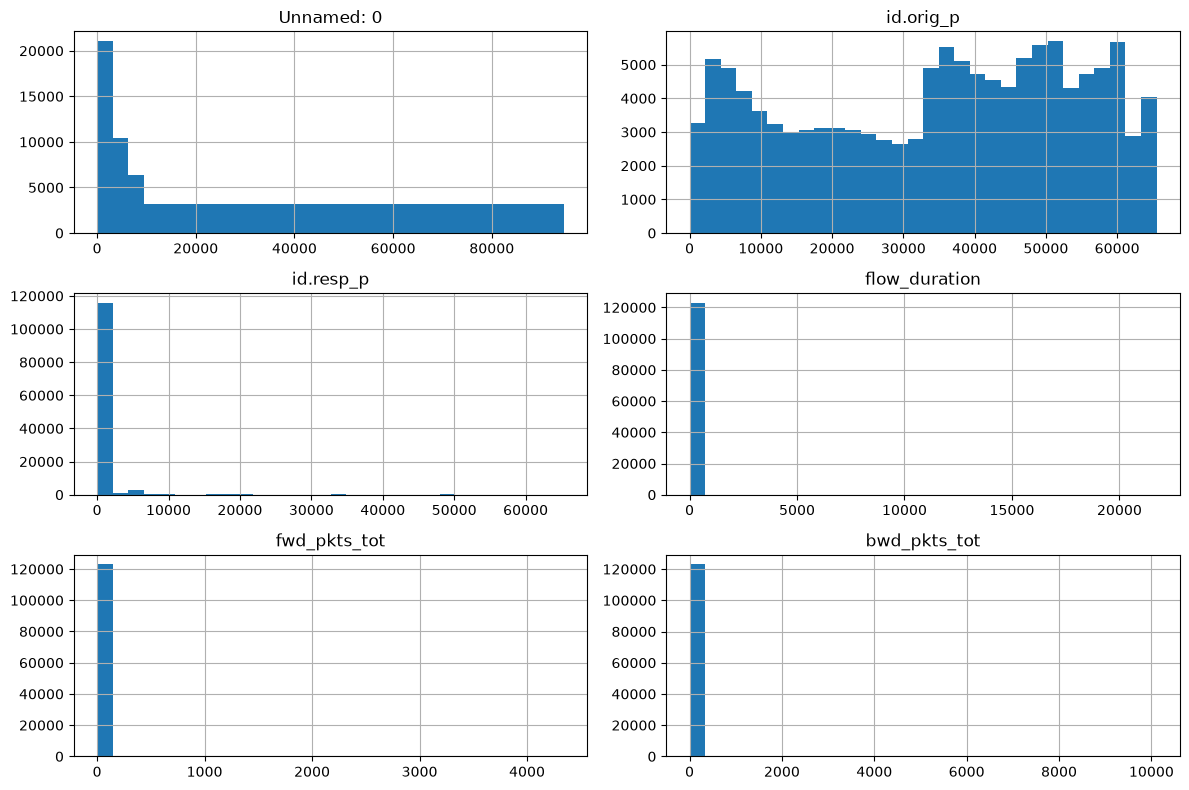

In [23]:
features_to_plot = numeric_columns[:6]

df[features_to_plot].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

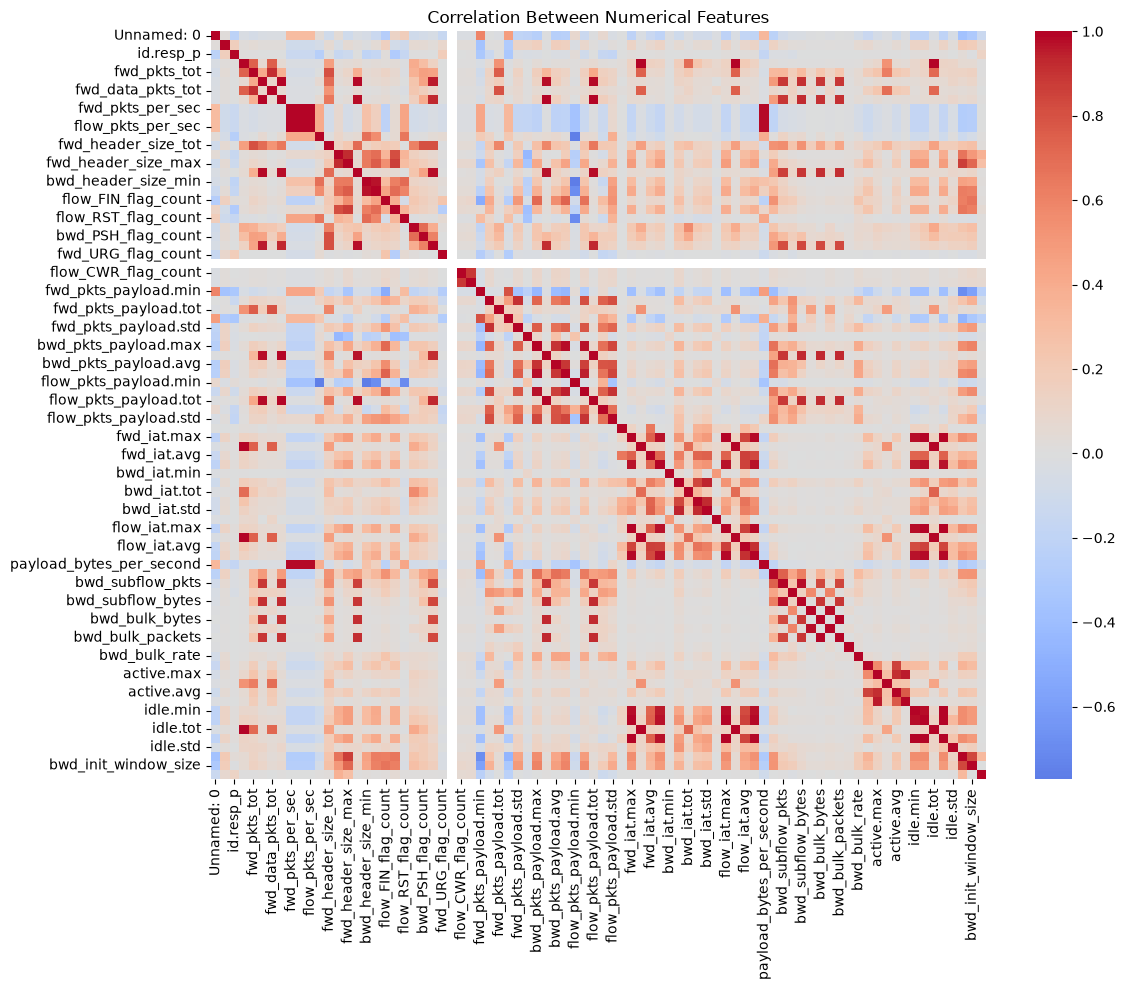

In [24]:
correlation = df[numeric_columns].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [25]:
print("Protocol distribution:")
print(df["proto"].value_counts())

Protocol distribution:
proto
tcp     110427
udp      12633
icmp        57
Name: count, dtype: int64


In [26]:
print("Service distribution:")
print(df["service"].value_counts())

Service distribution:
service
-         102861
dns         9753
mqtt        4132
http        3464
ssl         2663
ntp          121
dhcp          50
irc           43
ssh           28
radius         2
Name: count, dtype: int64


In [27]:
protocol_attack = pd.crosstab(
    df["proto"],
    df["Attack_type"]
)

protocol_attack

Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
proto,,,,,,,,,,,,
icmp,8,0,0,0,0,0,0,0,2,0,45,2
tcp,1927,529,94659,4146,29,25,2000,1002,142,2007,3779,182
udp,5815,5,0,0,8,3,0,0,2446,3,4284,69


In [28]:
top_services = df["service"].value_counts().head(10).index

service_attack = pd.crosstab(
    df[df["service"].isin(top_services)]["service"],
    df[df["service"].isin(top_services)]["Attack_type"]
)

service_attack

Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
service,,,,,,,,,,,,
-,546,6,94659,11,0,24,2000,1002,2411,2006,151,45
dhcp,26,2,0,0,0,0,0,0,3,0,14,5
dns,5583,3,0,0,8,3,0,0,31,3,4069,53
http,129,523,0,3,1,1,0,0,139,1,2667,0
irc,0,0,0,0,0,0,0,0,0,0,0,43
mqtt,0,0,0,4132,0,0,0,0,0,0,0,0
ntp,7,0,0,0,0,0,0,0,4,0,110,0
radius,0,0,0,0,0,0,0,0,2,0,0,0
ssh,0,0,0,0,28,0,0,0,0,0,0,0


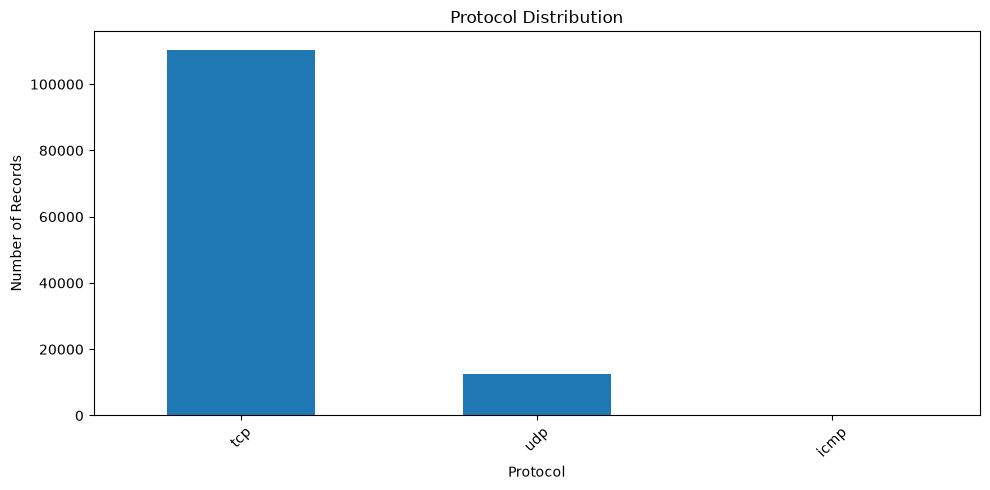

In [29]:
plt.figure(figsize=(10, 5))

df["proto"].value_counts().plot(kind="bar")

plt.title("Protocol Distribution")
plt.xlabel("Protocol")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

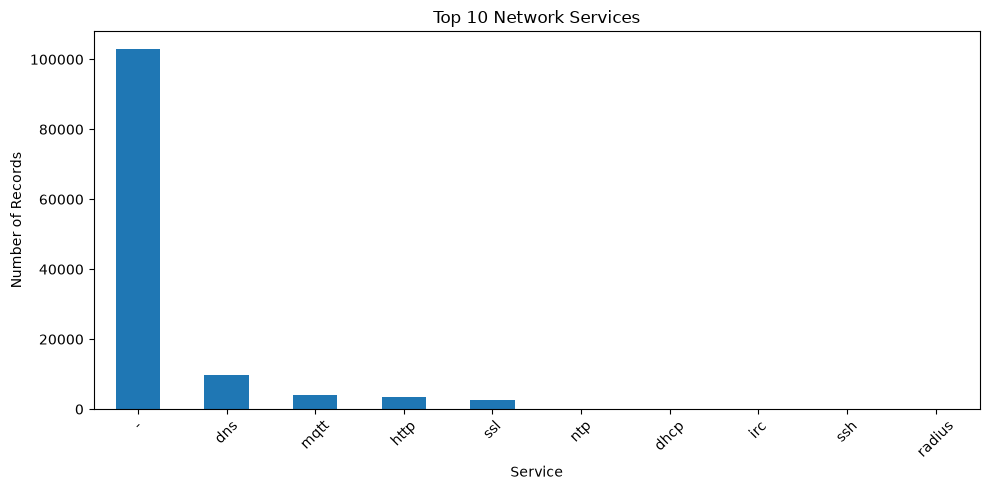

In [30]:
plt.figure(figsize=(10, 5))

df["service"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Network Services")
plt.xlabel("Service")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Check columns with unique values close to the number of rows

unique_counts = df.nunique().sort_values(ascending=False)

print(unique_counts.head(15))

Unnamed: 0                  94659
id.orig_p                   65478
payload_bytes_per_second    17238
flow_iat.std                17180
flow_iat.avg                16912
flow_iat.tot                16784
active.avg                  16756
active.tot                  16752
active.max                  16750
flow_iat.max                16520
active.min                  16438
flow_duration               16383
flow_pkts_per_sec           16111
fwd_pkts_per_sec            15892
bwd_pkts_per_sec            15428
dtype: int64


In [32]:
print("Unnamed: 0 unique values:", df["Unnamed: 0"].nunique())
print("Total rows:", len(df))

Unnamed: 0 unique values: 94659
Total rows: 123117


In [33]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
['bwd_URG_flag_count']


In [34]:
df_clean = df.copy()

print("Working copy created")
print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Working copy created
Original shape: (123117, 85)
Working copy shape: (123117, 85)


In [35]:
if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

print("Clean dataset shape:", df_clean.shape)

Clean dataset shape: (123117, 84)


In [36]:
# Remove constant columns
df_clean = df_clean.drop(columns=constant_columns)

print("Constant columns removed:", constant_columns)
print("New dataset shape:", df_clean.shape)

Constant columns removed: ['bwd_URG_flag_count']
New dataset shape: (123117, 83)


In [37]:
print("Attack_type present:", "Attack_type" in df_clean.columns)
print("Total columns:", len(df_clean.columns))

Attack_type present: True
Total columns: 83


In [38]:
X = df_clean.drop(columns=["Attack_type"])
y = df_clean["Attack_type"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (123117, 82)
Target (y): (123117,)


In [39]:
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Categorical features:")
print(categorical_features)

Categorical features:
['proto', 'service']


C:\Users\Admin\AppData\Local\Temp\ipykernel_31732\1976957250.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


In [40]:
numerical_features = X.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical features:", len(numerical_features))

Number of numerical features: 80


In [41]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Missing values in X: 0
Missing values in y: 0


In [42]:
from sklearn.preprocessing import OneHotEncoder


In [43]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_encoded = encoder.fit_transform(X[categorical_features])

print("Encoded categorical data shape:", X_encoded.shape)

Encoded categorical data shape: (123117, 13)


In [44]:
encoded_columns = encoder.get_feature_names_out(categorical_features)

X_encoded_df = pd.DataFrame(
    X_encoded,
    columns=encoded_columns,
    index=X.index
)

print("Encoded DataFrame shape:", X_encoded_df.shape)

Encoded DataFrame shape: (123117, 13)


In [45]:
X_final = pd.concat(
    [
        X[numerical_features],
        X_encoded_df
    ],
    axis=1
)

print("Final feature shape:", X_final.shape)

Final feature shape: (123117, 93)


In [46]:
print("Non-numeric columns:")
print(X_final.select_dtypes(exclude=np.number).columns.tolist())


Non-numeric columns:
[]


Split the dataset into training and testing data
 
80% training data → used to train the Random Forest.

20% testing data → used to evaluate it on unseen data.

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (98493, 93)
Testing features: (24624, 93)
Training target: (98493,)
Testing target: (24624,)


In [49]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training class distribution:
Attack_type
DOS_SYN_Hping                 0.769
Thing_Speak                   0.066
ARP_poisioning                0.063
MQTT_Publish                  0.034
NMAP_UDP_SCAN                 0.021
NMAP_XMAS_TREE_SCAN           0.016
NMAP_OS_DETECTION             0.016
NMAP_TCP_scan                 0.008
DDOS_Slowloris                0.004
Wipro_bulb                    0.002
Metasploit_Brute_Force_SSH    0.000
NMAP_FIN_SCAN                 0.000
Name: proportion, dtype: float64

Testing class distribution:
Attack_type
DOS_SYN_Hping                 0.769
Thing_Speak                   0.066
ARP_poisioning                0.063
MQTT_Publish                  0.034
NMAP_UDP_SCAN                 0.021
NMAP_XMAS_TREE_SCAN           0.016
NMAP_OS_DETECTION             0.016
NMAP_TCP_scan                 0.008
DDOS_Slowloris                0.004
Wipro_bulb                    0.002
Metasploit_Brute_Force_SSH    0.000
NMAP_FIN_SCAN                 0.000
Name: proportion, dty

In [50]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train_raw.shape)
print("Testing data:", X_test_raw.shape)

Training data: (98493, 82)
Testing data: (24624, 82)


In [51]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(
    X_train_raw[categorical_features]
)

X_test_cat = encoder.transform(
    X_test_raw[categorical_features]
)

print("Training categorical data:", X_train_cat.shape)
print("Testing categorical data:", X_test_cat.shape)

Training categorical data: (98493, 13)
Testing categorical data: (24624, 13)


In [52]:
encoded_columns = encoder.get_feature_names_out(
    categorical_features
)

X_train_cat_df = pd.DataFrame(
    X_train_cat,
    columns=encoded_columns,
    index=X_train_raw.index
)

X_test_cat_df = pd.DataFrame(
    X_test_cat,
    columns=encoded_columns,
    index=X_test_raw.index
)

In [53]:
X_train_final = pd.concat(
    [
        X_train_raw[numerical_features],
        X_train_cat_df
    ],
    axis=1
)

X_test_final = pd.concat(
    [
        X_test_raw[numerical_features],
        X_test_cat_df
    ],
    axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (98493, 93)
Final testing shape: (24624, 93)


In [54]:
print("Training missing values:", X_train_final.isnull().sum().sum())
print("Testing missing values:", X_test_final.isnull().sum().sum())

print("Training data type:", X_train_final.dtypes.value_counts())

Training missing values: 0
Testing missing values: 0
Training data type: float64    69
int64      24
Name: count, dtype: int64


Train the baseline Random Forest model

In [55]:
from sklearn.ensemble import RandomForestClassifier

In [56]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [57]:
rf_model.fit(X_train_final, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [58]:
y_pred = rf_model.predict(X_test_final)

print("Predictions completed!")

Predictions completed!


In [59]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2), "%")

Accuracy: 0.9985
Accuracy (%): 99.85 %


In [60]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      0.98      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      0.99      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.94      0.96        51

                  accuracy                           1.00     24624
                 macro avg       0.98      0.9

<Figure size 1200x1000 with 0 Axes>

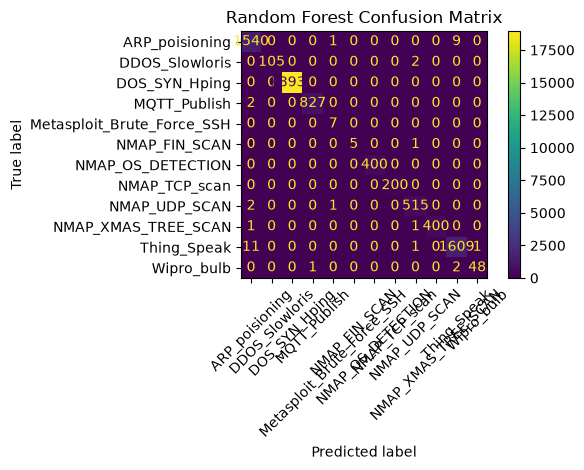

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)
f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("Model Performance")
print("-----------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Model Performance
-----------------
Accuracy : 0.9985
Precision: 0.9986
Recall   : 0.9985
F1-Score : 0.9985

Detailed Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      0.98      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      0.99      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98     

In [63]:
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("Macro F1-Score:", round(macro_f1, 4))

Macro F1-Score: 0.9756


In [64]:
feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
29,fwd_pkts_payload.avg,0.087338
1,id.resp_p,0.070351
26,fwd_pkts_payload.min,0.069595
27,fwd_pkts_payload.max,0.047730
59,fwd_subflow_bytes,0.041799
2,flow_duration,0.035345
83,service_-,0.030986
52,flow_iat.max,0.030522
28,fwd_pkts_payload.tot,0.029452
70,active.avg,0.029210


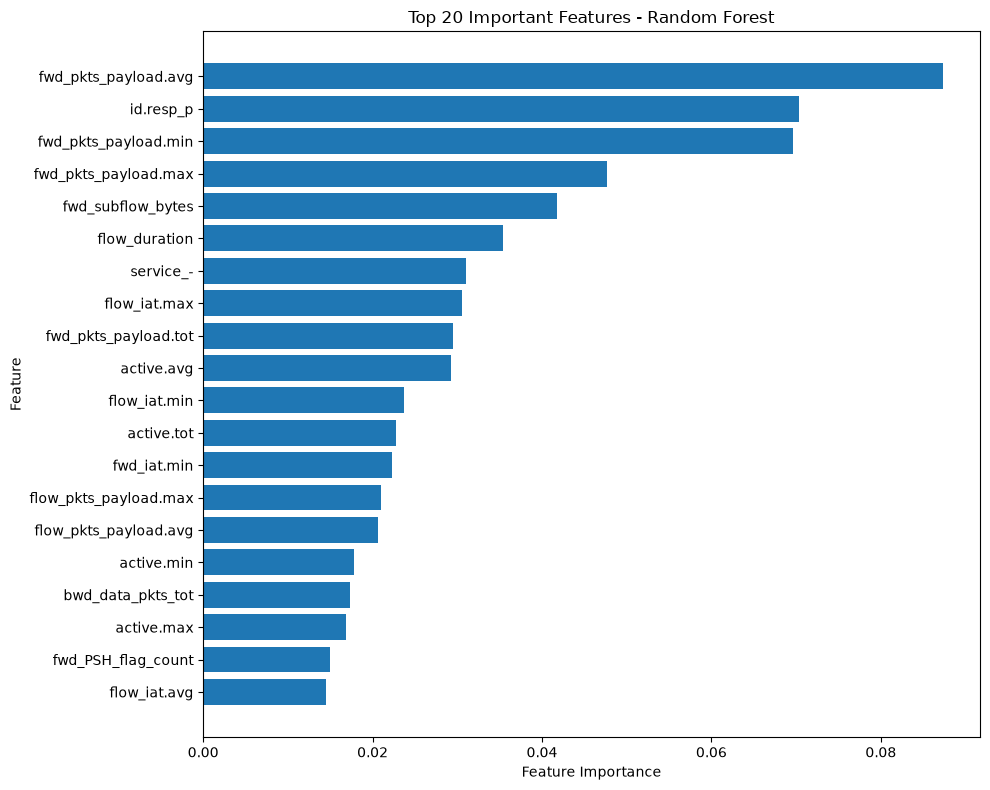

In [65]:
top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Improve the model for imbalanced classes

In [66]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train_final, y_train)

print("Balanced Random Forest training completed!")

Balanced Random Forest training completed!


In [67]:
y_pred_balanced = rf_balanced.predict(X_test_final)

print("Balanced model predictions completed!")

Balanced model predictions completed!


In [68]:
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)

balanced_macro_f1 = f1_score(
    y_test,
    y_pred_balanced,
    average="macro",
    zero_division=0
)

balanced_weighted_f1 = f1_score(
    y_test,
    y_pred_balanced,
    average="weighted",
    zero_division=0
)

print("Balanced Random Forest Performance")
print("----------------------------------")
print("Accuracy       :", round(balanced_accuracy, 4))
print("Macro F1-Score :", round(balanced_macro_f1, 4))
print("Weighted F1    :", round(balanced_weighted_f1, 4))

Balanced Random Forest Performance
----------------------------------
Accuracy       : 0.9984
Macro F1-Score : 0.9608
Weighted F1    : 0.9984


In [69]:
print(classification_report(
    y_test,
    y_pred_balanced,
    zero_division=0
))

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      0.98      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       0.62      0.83      0.71         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      0.99      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.98      0.98        51

                  accuracy                           1.00     24624
                 macro avg       0.95      0.9

In [70]:
feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20).to_string(index=False))

Top 20 Important Features:
              Feature  Importance
 fwd_pkts_payload.avg    0.087338
            id.resp_p    0.070351
 fwd_pkts_payload.min    0.069595
 fwd_pkts_payload.max    0.047730
    fwd_subflow_bytes    0.041799
        flow_duration    0.035345
            service_-    0.030986
         flow_iat.max    0.030522
 fwd_pkts_payload.tot    0.029452
           active.avg    0.029210
         flow_iat.min    0.023758
           active.tot    0.022731
          fwd_iat.min    0.022283
flow_pkts_payload.max    0.021007
flow_pkts_payload.avg    0.020590
           active.min    0.017767
    bwd_data_pkts_tot    0.017310
           active.max    0.016914
   fwd_PSH_flag_count    0.015004
         flow_iat.avg    0.014532


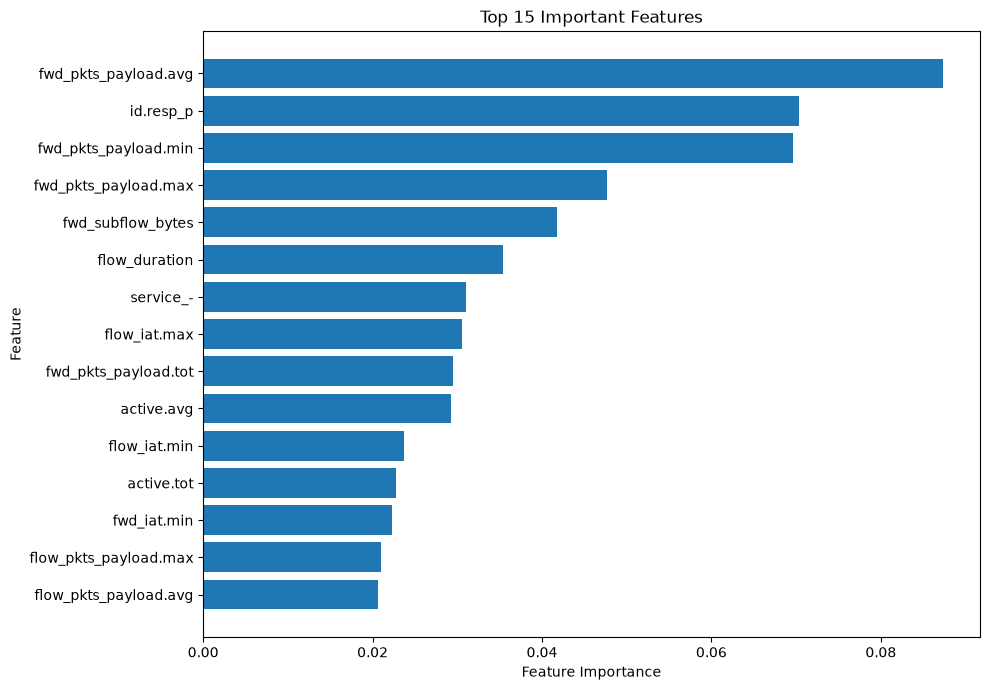

In [71]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [72]:
print("Total features:", X_train_final.shape[1])

Total features: 93


In [73]:
top_20_features = feature_importance.head(20)["Feature"].tolist()

X_train_top20 = X_train_final[top_20_features]
X_test_top20 = X_test_final[top_20_features]

print("Top 20 feature dataset created")
print("Training shape:", X_train_top20.shape)
print("Testing shape :", X_test_top20.shape)

Top 20 feature dataset created
Training shape: (98493, 20)
Testing shape : (24624, 20)


In [74]:
rf_top20 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_top20.fit(X_train_top20, y_train)

y_pred_top20 = rf_top20.predict(X_test_top20)

print("Top 20 feature Random Forest training completed!")

Top 20 feature Random Forest training completed!


In [75]:
from sklearn.metrics import accuracy_score, f1_score

top20_accuracy = accuracy_score(y_test, y_pred_top20)
top20_macro_f1 = f1_score(
    y_test,
    y_pred_top20,
    average="macro",
    zero_division=0
)
top20_weighted_f1 = f1_score(
    y_test,
    y_pred_top20,
    average="weighted",
    zero_division=0
)

print("Top 20 Features Model")
print("---------------------")
print("Accuracy       :", round(top20_accuracy, 4))
print("Macro F1-Score :", round(top20_macro_f1, 4))
print("Weighted F1    :", round(top20_weighted_f1, 4))

Top 20 Features Model
---------------------
Accuracy       : 0.9901
Macro F1-Score : 0.9036
Weighted F1    : 0.99


In [76]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_final, y_train)

y_pred_dt = dt_model.predict(X_test_final)

print("Decision Tree training completed!")

Decision Tree training completed!


In [77]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_macro_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="macro",
    zero_division=0
)

dt_weighted_f1 = f1_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

print("Decision Tree Performance")
print("-------------------------")
print("Accuracy       :", round(dt_accuracy, 4))
print("Macro F1-Score :", round(dt_macro_f1, 4))
print("Weighted F1    :", round(dt_weighted_f1, 4))

Decision Tree Performance
-------------------------
Accuracy       : 0.998
Macro F1-Score : 0.9662
Weighted F1    : 0.998


In [78]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Decision Tree",
        "Random Forest - Top 20 Features"
    ],
    "Features": [
        X_train_final.shape[1],
        X_train_final.shape[1],
        X_train_top20.shape[1]
    ],
    "Accuracy": [
        accuracy,
        dt_accuracy,
        top20_accuracy
    ],
    "Macro F1": [
        macro_f1,
        dt_macro_f1,
        top20_macro_f1
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        dt_weighted_f1,
        top20_weighted_f1
    ]
})

comparison

,Model,Features,Accuracy,Macro F1,Weighted F1
0,Random Forest,93,0.998538,0.975573,0.998540
1,Decision Tree,93,0.997969,0.966196,0.997967
2,Random Forest - Top 20 Features,20,0.990091,0.903616,0.989972


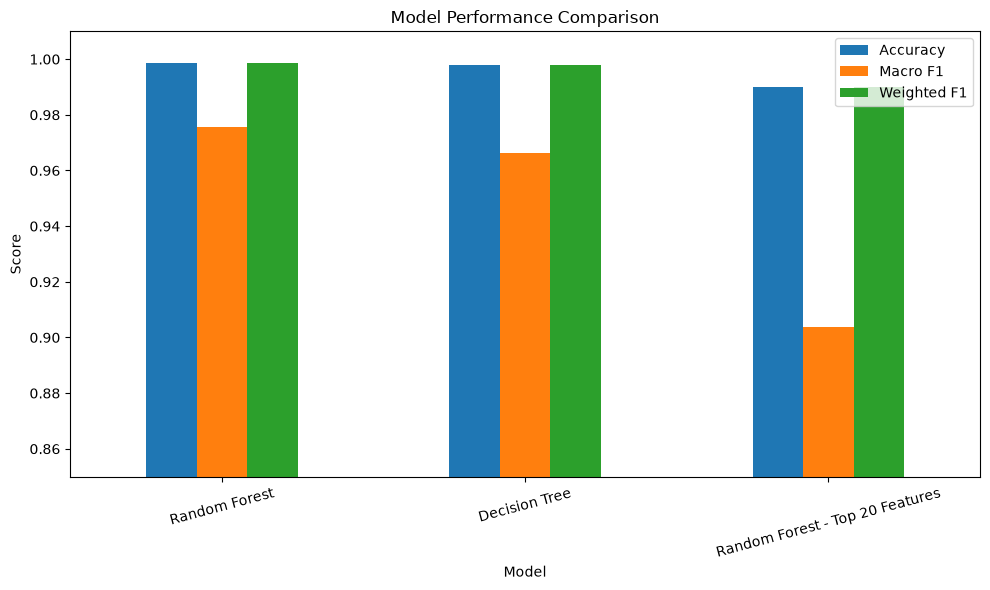

In [79]:
comparison_plot = comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0.85, 1.01)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Hyperparameter Tuning

In [80]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5]
}

rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_final, y_train)

print("Hyperparameter tuning completed!")
print("Best parameters:")
print(grid_search.best_params_)
print("Best CV Macro F1:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Hyperparameter tuning completed!
Best parameters:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Macro F1: 0.9667


In [81]:
best_rf = grid_search.best_estimator_

best_rf.fit(X_train_final, y_train)

y_pred_tuned = best_rf.predict(X_test_final)

print("Tuned Random Forest training completed!")

Tuned Random Forest training completed!


In [82]:
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

tuned_macro_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average="macro",
    zero_division=0
)

tuned_weighted_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy       :", round(tuned_accuracy, 4))
print("Macro F1-Score :", round(tuned_macro_f1, 4))
print("Weighted F1    :", round(tuned_weighted_f1, 4))

Tuned Random Forest Performance
--------------------------------
Accuracy       : 0.9984
Macro F1-Score : 0.9751
Weighted F1    : 0.9984


In [83]:
print("Random Forest Comparison")
print("------------------------")

print("Baseline Random Forest")
print("Accuracy       :", round(accuracy, 4))
print("Macro F1       :", round(macro_f1, 4))
print("Weighted F1    :", round(
    f1_score(y_test, y_pred, average="weighted", zero_division=0), 4
))

print("\nTuned Random Forest")
print("Accuracy       :", round(tuned_accuracy, 4))
print("Macro F1       :", round(tuned_macro_f1, 4))
print("Weighted F1    :", round(tuned_weighted_f1, 4))

Random Forest Comparison
------------------------
Baseline Random Forest
Accuracy       : 0.9985
Macro F1       : 0.9756
Weighted F1    : 0.9985

Tuned Random Forest
Accuracy       : 0.9984
Macro F1       : 0.9751
Weighted F1    : 0.9984


In [84]:
print("Tuned Random Forest Classification Report")
print("-----------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

Tuned Random Forest Classification Report
-----------------------------------------
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      0.99      1.00       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       1.00      0.99      1.00       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.92      0.95        51

                  accuracy    

In [86]:
final_model = rf_model

print("Final Model Selected")
print("--------------------")
print("Model: Random Forest")
print("n_estimators:", final_model.n_estimators)
print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print(
    "Weighted F1:",
    round(
        f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        4
    )
)

Final Model Selected
--------------------
Model: Random Forest
n_estimators: 100
Accuracy: 0.9985
Macro F1: 0.9756
Weighted F1: 0.9985


In [87]:
import os
import joblib

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save final Random Forest model
joblib.dump(final_model, "../models/random_forest.pkl")

# Save the encoder
joblib.dump(encoder, "../models/encoder.pkl")

print("Final model and encoder saved successfully!")

Final model and encoder saved successfully!


In [88]:
print("Model file exists:", os.path.exists("../models/random_forest.pkl"))
print("Encoder file exists:", os.path.exists("../models/encoder.pkl"))

Model file exists: True
Encoder file exists: True


In [89]:
joblib.dump(
    {
        "numerical_features": numerical_features,
        "categorical_features": categorical_features
    },
    "../models/feature_config.pkl"
)

print("Feature configuration saved successfully!")

Feature configuration saved successfully!


In [90]:
print(
    "Feature config exists:",
    os.path.exists("../models/feature_config.pkl")
)

Feature config exists: True


In [91]:
import joblib

test_model = joblib.load("../models/random_forest.pkl")
test_encoder = joblib.load("../models/encoder.pkl")
test_config = joblib.load("../models/feature_config.pkl")

print("Model loaded successfully!")
print("Encoder loaded successfully!")
print("Feature configuration loaded successfully!")

print("\nModel features:", len(test_model.feature_names_in_))
print("Categorical features:", test_config["categorical_features"])
print("Numerical features:", len(test_config["numerical_features"]))

Model loaded successfully!
Encoder loaded successfully!
Feature configuration loaded successfully!

Model features: 93
Categorical features: ['proto', 'service']
Numerical features: 80


In [92]:
# Take one real record from the dataset
sample = df_clean.iloc[0].copy()

# Store the actual attack type for comparison
actual_attack = sample["Attack_type"]

# Remove the target variable
sample_input = sample.drop("Attack_type").to_dict()

# Import prediction function
import sys
sys.path.append("../src")

from predict import predict_attack

# Make prediction
predicted_attack = predict_attack(sample_input)

print("CyberGuard Prediction Test")
print("--------------------------")
print("Actual Attack Type    :", actual_attack)
print("Predicted Attack Type :", predicted_attack)

if actual_attack == predicted_attack:
    print("\nPrediction Result: CORRECT")
else:
    print("\nPrediction Result: INCORRECT")

CyberGuard Prediction Test
--------------------------
Actual Attack Type    : MQTT_Publish
Predicted Attack Type : MQTT_Publish

Prediction Result: CORRECT


In [93]:
print("CyberGuard Multiple Prediction Test")
print("-----------------------------------")

test_samples = df_clean.sample(10, random_state=42)

correct = 0

for index, row in test_samples.iterrows():

    actual_attack = row["Attack_type"]

    sample_input = row.drop("Attack_type").to_dict()

    predicted_attack = predict_attack(sample_input)

    result = "CORRECT" if actual_attack == predicted_attack else "INCORRECT"

    if result == "CORRECT":
        correct += 1

    print(
        f"Row {index} | "
        f"Actual: {actual_attack} | "
        f"Predicted: {predicted_attack} | "
        f"{result}"
    )

print("\nMultiple Prediction Test")
print("------------------------")
print("Correct predictions:", correct)
print("Total predictions  :", len(test_samples))
print(
    "Test accuracy      :",
    round(correct / len(test_samples), 2)
)

CyberGuard Multiple Prediction Test
-----------------------------------
Row 76235 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 36557 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 84102 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 3245 | Actual: MQTT_Publish | Predicted: MQTT_Publish | CORRECT
Row 114798 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 98863 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 98982 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 60129 | Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | CORRECT
Row 121828 | Actual: NMAP_XMAS_TREE_SCAN | Predicted: NMAP_XMAS_TREE_SCAN | CORRECT
Row 6700 | Actual: Thing_Speak | Predicted: Thing_Speak | CORRECT

Multiple Prediction Test
------------------------
Correct predictions: 10
Total predictions  : 10
Test accuracy      : 1.0


In [95]:
import requests
import json

# Select one real record
sample = df_clean.iloc[0]

# Store actual attack type
actual_attack = sample["Attack_type"]

# Remove target variable
sample_input = sample.drop("Attack_type")

# Convert to JSON-safe Python data
sample_data = json.loads(sample_input.to_json())

# Send request to FastAPI
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json={"data": sample_data}
)

print("CyberGuard API Test")
print("-------------------")
print("HTTP Status Code:", response.status_code)
print("Actual Attack   :", actual_attack)
print("API Response    :", response.json())

CyberGuard API Test
-------------------
HTTP Status Code: 200
Actual Attack   : MQTT_Publish
API Response    : {'predicted_attack_type': 'MQTT_Publish', 'confidence': 1.0}


In [96]:
import requests
import json

# Select one record from each available attack type
samples = df_clean.groupby("Attack_type", group_keys=False).head(1)

print("CyberGuard API Multi-Class Test")
print("--------------------------------")

correct = 0
total = len(samples)

for index, row in samples.iterrows():

    actual_attack = row["Attack_type"]

    sample_input = row.drop("Attack_type")
    sample_data = json.loads(sample_input.to_json())

    response = requests.post(
        "http://127.0.0.1:8000/predict",
        json={"data": sample_data}
    )

    result = response.json()

    predicted_attack = result["predicted_attack_type"]
    confidence = result["confidence"]

    if actual_attack == predicted_attack:
        status = "CORRECT"
        correct += 1
    else:
        status = "INCORRECT"

    print(
        f"Actual: {actual_attack} | "
        f"Predicted: {predicted_attack} | "
        f"Confidence: {confidence:.2%} | "
        f"{status}"
    )

print("\nAPI Multi-Class Test")
print("--------------------")
print("Correct predictions:", correct)
print("Total classes tested:", total)
print("Test accuracy:", round(correct / total, 4))

CyberGuard API Multi-Class Test
--------------------------------
Actual: MQTT_Publish | Predicted: MQTT_Publish | Confidence: 100.00% | CORRECT
Actual: Thing_Speak | Predicted: Thing_Speak | Confidence: 100.00% | CORRECT
Actual: Wipro_bulb | Predicted: Wipro_bulb | Confidence: 100.00% | CORRECT
Actual: ARP_poisioning | Predicted: ARP_poisioning | Confidence: 99.77% | CORRECT
Actual: DDOS_Slowloris | Predicted: DDOS_Slowloris | Confidence: 75.00% | CORRECT
Actual: DOS_SYN_Hping | Predicted: DOS_SYN_Hping | Confidence: 100.00% | CORRECT
Actual: Metasploit_Brute_Force_SSH | Predicted: Metasploit_Brute_Force_SSH | Confidence: 61.00% | CORRECT
Actual: NMAP_FIN_SCAN | Predicted: NMAP_FIN_SCAN | Confidence: 65.00% | CORRECT
Actual: NMAP_OS_DETECTION | Predicted: NMAP_OS_DETECTION | Confidence: 98.00% | CORRECT
Actual: NMAP_TCP_scan | Predicted: NMAP_TCP_scan | Confidence: 84.00% | CORRECT
Actual: NMAP_UDP_SCAN | Predicted: NMAP_UDP_SCAN | Confidence: 97.00% | CORRECT
Actual: NMAP_XMAS_TREE_SC

In [97]:
import requests
import json

sample = df_clean.iloc[0]

actual_attack = sample["Attack_type"]

sample_input = sample.drop("Attack_type")
sample_data = json.loads(sample_input.to_json())

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json={"data": sample_data}
)

print("CyberGuard API Test")
print("-------------------")
print("HTTP Status Code:", response.status_code)
print("Actual Attack   :", actual_attack)
print("API Response    :", response.json())

CyberGuard API Test
-------------------
HTTP Status Code: 200
Actual Attack   : MQTT_Publish
API Response    : {'predicted_attack_type': 'MQTT_Publish', 'confidence': 1.0, 'message': 'Network traffic classified successfully'}


In [98]:
import requests
import json

sample = df_clean.iloc[0]

actual_attack = sample["Attack_type"]

sample_input = sample.drop("Attack_type")
sample_data = json.loads(sample_input.to_json())

response = requests.post(
    "http://127.0.0.1:8000/predict",
    json={"data": sample_data}
)

print("CyberGuard API Test")
print("-------------------")
print("HTTP Status Code:", response.status_code)
print("Actual Attack   :", actual_attack)
print("API Response    :", response.json())

CyberGuard API Test
-------------------
HTTP Status Code: 200
Actual Attack   : MQTT_Publish
API Response    : {'predicted_attack_type': 'MQTT_Publish', 'confidence': 1.0, 'message': 'Network traffic classified successfully'}
